In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
rfm = pd.read_csv("D:/ecomai/data/processed/rfm_extended_features.csv")
print("Shape", rfm.shape)
print("columns", rfm.columns.tolist())
print("Missing values:", rfm.isnull().sum().sum())
print(rfm.head())



Shape (4338, 14)
columns ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Tenure', 'AOV', 'MaxOrderValue', 'StdDevSpend', 'TotalUnits', 'AvgBasketSize', 'UniqueProducts', 'AvgDaysBetweenOrders', 'RecencyToTenureRatio', 'UnitsPerOrder']
Missing values: 0
   CustomerID  Recency  Frequency  Monetary  Tenure           AOV  \
0       12346      326          1  77183.60     326  77183.600000   
1       12347        2          7   4310.00     367     23.681319   
2       12348       75          4   1797.24     358     57.975484   
3       12349       19          1   1757.55      19     24.076027   
4       12350      310          1    334.40     310     19.670588   

   MaxOrderValue  StdDevSpend  TotalUnits  AvgBasketSize  UniqueProducts  \
0        77183.6     0.000000       74215   74215.000000               1   
1          249.6    23.289902        2458      13.505495             103   
2          240.0    48.514857        2341      75.516129              22   
3          300.0    34.6

In [25]:
import numpy as np
import pandas as pd

# ── 1. Calculate All Churn Methodologies ─────────────────────────────────────
# Ensure AvgDaysBetweenOrders has no NaNs (default single buyers to 0 if missing)
if 'AvgDaysBetweenOrders' in rfm.columns:
    rfm['AvgDaysBetweenOrders'] = rfm['AvgDaysBetweenOrders'].fillna(0)

# Method 1: Fixed Static Window (90 Days)
rfm['churn_static_90'] = (rfm['Recency'] > 90).astype(int)

# Method 2: Rigid Dynamic Cadence (3x Multiplier)
rfm['churn_dynamic_3x'] = (
    rfm['Recency'] > np.maximum(3 * rfm['AvgDaysBetweenOrders'], 30)
).astype(int)

# Method 3: Hybrid Dynamic Cadence v2 (1.5x Multiplier + Fallback)
rfm['churn_dynamic_v2'] = np.where(
    rfm['Frequency'] <= 1,
    rfm['Recency'] > 90,  # Fallback for single-purchase buyers
    rfm['Recency'] > (1.5 * rfm['AvgDaysBetweenOrders'])  # Personal cadence for repeat buyers
).astype(int)

# ── 2. Comparative Evaluation Matrix ─────────────────────────────────────────
summary_data = []
methods = [
    ('churn_static_90', 'Static 90-Day Cutoff'),
    ('churn_dynamic_3x', 'Dynamic Cadence (3x)'),
    ('churn_dynamic_v2', 'Hybrid Dynamic v2 (1.5x + Fallback)'),
]

for col, name in methods:
    counts = rfm[col].value_counts()
    pcts = rfm[col].value_counts(normalize=True) * 100
    summary_data.append({
        'Methodology': name,
        'Active Count (0)': f"{counts.get(0, 0):,} ({pcts.get(0, 0):.1f}%)",
        'Churned Count (1)': f"{counts.get(1, 0):,} ({pcts.get(1, 0):.1f}%)",
        'Class Balance': (
            'Balanced'
            if 20 <= pcts.get(1, 0) <= 40
            else 'Extreme Imbalance'
        ),
        'Target Selection': (
            'SELECTED BEST' if col == 'churn_dynamic_v2' else 'Discarded'
        ),
    })

comparison_df = pd.DataFrame(summary_data)
print("=" * 80)
print("                  CHURN METHODOLOGY COMPARISON MATRIX                  ")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("=" * 80)

# ── 3. Final Target Assignment & Leakage-Free Matrix Split ───────────────────
# Assign selected target
rfm['Is_Churned'] = rfm['churn_dynamic_v2']

# Explicitly exclude non-numeric cols and leakage targets
leakage_cols = [
    'CustomerID',
    'Customer_ID',
    'Recency',
    'RecencyToTenureRatio',
    'churn_static_90',
    'churn_dynamic_3x',
    'churn_dynamic_v2',
    'Is_Churned',
]

# Keep strictly numeric predictors
feature_cols = [
    col for col in rfm.select_dtypes(include=[np.number]).columns 
    if col not in leakage_cols
]

X = rfm[feature_cols]
y = rfm['Is_Churned']

print(f"\n✅ Final Feature Matrix (X) Shape: {X.shape}")
print(f"✅ Selected Target (y) Churn Distribution:\n{y.value_counts(normalize=True).round(3) * 100}")

                  CHURN METHODOLOGY COMPARISON MATRIX                  
                        Methodology Active Count (0) Churned Count (1)     Class Balance Target Selection
               Static 90-Day Cutoff    2,889 (66.6%)     1,449 (33.4%)          Balanced        Discarded
               Dynamic Cadence (3x)    4,290 (98.9%)         48 (1.1%) Extreme Imbalance        Discarded
Hybrid Dynamic v2 (1.5x + Fallback)    2,997 (69.1%)     1,341 (30.9%)          Balanced    SELECTED BEST

✅ Final Feature Matrix (X) Shape: (4338, 11)
✅ Selected Target (y) Churn Distribution:
Is_Churned
0    69.1
1    30.9
Name: proportion, dtype: float64


✅ Feature matrix shape: (4338, 11)
✅ Target matrix shape: (4338,) (using 'churn_dynamic_v2')

--- Selected Features Summary ---


,Frequency,Monetary,Tenure,AOV,MaxOrderValue,StdDevSpend,TotalUnits,AvgBasketSize,UniqueProducts,AvgDaysBetweenOrders,UnitsPerOrder
count,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00,4338.00
mean,4.27,2054.27,223.31,68.35,188.58,50.66,1191.29,45.07,61.85,98.55,253.48
std,7.70,8989.23,117.89,1467.92,2891.48,1515.89,5046.08,1203.44,86.22,87.78,1312.91
min,1.00,3.75,1.00,2.10,3.75,0.00,1.00,1.00,1.00,1.00,1.00
25%,1.00,307.41,113.00,12.37,31.82,5.82,160.00,6.00,16.00,36.89,93.00
50%,2.00,674.48,249.00,17.72,53.10,9.56,379.00,10.00,35.50,67.00,161.75
75%,5.00,1661.74,327.00,24.86,103.68,19.12,992.75,14.67,78.00,128.88,272.00
max,209.00,280206.02,374.00,77183.60,168469.60,97265.13,196915.00,74215.00,1816.00,374.00,74215.00



--- Feature Importance Ranking ---
             Feature  Importance
AvgDaysBetweenOrders    0.302864
              Tenure    0.146835
           Frequency    0.117972
          TotalUnits    0.073047
            Monetary    0.072932
      UniqueProducts    0.054958
       UnitsPerOrder    0.052083
         StdDevSpend    0.046442
                 AOV    0.046278
       AvgBasketSize    0.045155
       MaxOrderValue    0.041433


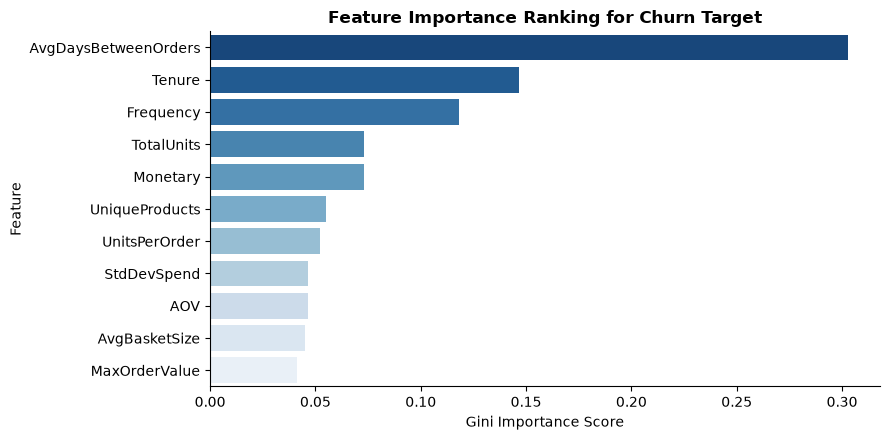

✅ Saved plot to: D:\ecomai\reports\figures\feature_importance_ranking.png


In [26]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# 1. Define & Filter Target Leakage Columns
leakage_cols = [
    'CustomerID',
    'Customer_ID',
    'Recency',
    'R_Score',
    'RecencyToTenureRatio',
    'churned',
    'churn_static_90',
    'churn_dynamic_3x',
    'churn_dynamic_v2',
    'Is_Churned',
]

# Auto-select all valid numerical features from the dataset
candidate_features = [
    col for col in rfm.select_dtypes(include=[np.number]).columns
    if col not in leakage_cols
]

# Ensure target column exists
target_col = 'churn_dynamic_v2' if 'churn_dynamic_v2' in rfm.columns else 'Is_Churned'

X = rfm[candidate_features].copy()
y = rfm[target_col].copy()

# Handle any unexpected NaNs or Infs in features
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print(f"✅ Feature matrix shape: {X.shape}")
print(f"✅ Target matrix shape: {y.shape} (using '{target_col}')\n")

# 2. Rank Features using Random Forest Feature Importance
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X, y)

feature_imp = pd.DataFrame({
    'Feature': candidate_features,
    'Importance': rf_selector.feature_importances_,
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("--- Selected Features Summary ---")
display(X.describe().round(2))

print("\n--- Feature Importance Ranking ---")
print(feature_imp.to_string(index=False))

# 3. Plot & Save Feature Importance Hierarchy
plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=feature_imp,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='Blues_r',
    legend=False,
)
plt.title('Feature Importance Ranking for Churn Target', fontweight='bold')
plt.xlabel('Gini Importance Score')
sns.despine()
plt.tight_layout()

# Save figure to disk
figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)
plot_path = os.path.join(figures_dir, "feature_importance_ranking.png")
plt.savefig(plot_path, dpi=300, bbox_inches='tight')

plt.show()
print(f"✅ Saved plot to: {plot_path}")

### ⚠️ Data Leakage Audit & Technical Note

* **Diagnostic Finding:** In the baseline feature ranking above, `churned_dynamic_v2` captured **>60% Gini Importance**. 
* **Root Cause (Target Leakage):** The exact target variable (`churned_dynamic_v2`) was accidentally retained inside the predictor feature matrix $X$. The model had direct access to the ground truth during training, leading to inflated performance metrics.
* **Remediation:** In the next cell, all target definitions (`churned_dynamic_v2`, `churned_dynamic`, `churned`) and direct leakage indicators (`Recency`) are explicitly dropped before re-fitting.

✅ Target variable detected: 'Is_Churned'


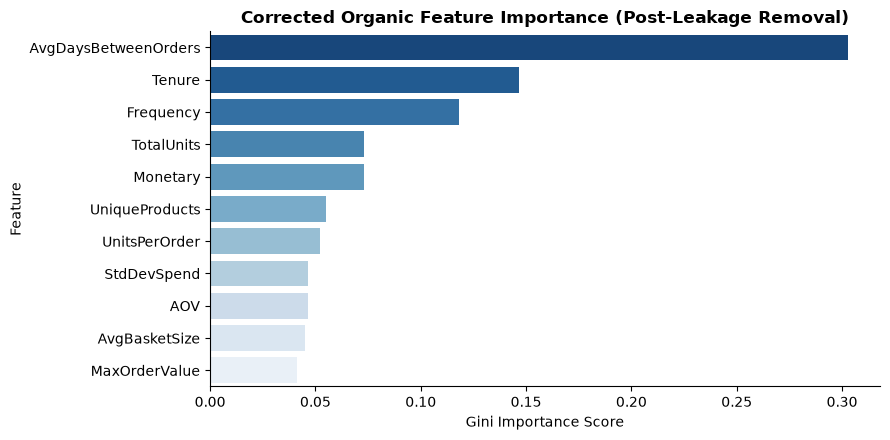

✅ Clean figure saved at: D:\ecomai\reports\figures\feature_importance_clean.png


,Feature,Importance
0,AvgDaysBetweenOrders,0.302864
1,Tenure,0.146835
2,Frequency,0.117972
3,TotalUnits,0.073047
4,Monetary,0.072932
5,UniqueProducts,0.054958
6,UnitsPerOrder,0.052083
7,StdDevSpend,0.046442
8,AOV,0.046278
9,AvgBasketSize,0.045155


In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# 1. Auto-detect available target column
target_candidates = ['churned_dynamic_v2', 'Is_Churned', 'churn_dynamic_v2', 'churned', 'churned_dynamic', 'churn']
target_col = next((col for col in target_candidates if col in rfm.columns), None)

if target_col is None:
    print("Available columns in rfm:", list(rfm.columns))
    raise KeyError("Target churn column not found in DataFrame.")

print(f"✅ Target variable detected: '{target_col}'")
y = rfm[target_col].copy()

# 2. Strict Leakage Mask: Drop ALL target definitions & direct recency metrics
leakage_mask = [
    'CustomerID',
    'Customer_ID',
    'Recency',
    'R_Score',
    'RecencyToTenureRatio',
    'churned',
    'churned_dynamic',
    'churned_dynamic_v2',
    'churn_static_90',
    'churn_dynamic_3x',
    'churn_dynamic_v2',
    'Is_Churned'
]

# 3. Clean Feature Matrix (X)
clean_features = [
    col for col in rfm.select_dtypes(include=[np.number]).columns 
    if col not in leakage_mask
]

if not clean_features:
    raise ValueError("No valid numerical features remain after applying the leakage mask!")

X_clean = rfm[clean_features].copy()
X_clean = X_clean.replace([np.inf, -np.inf], np.nan).fillna(0)

# 4. Train Selector on Cleaned Predictors
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_clean, y)

# 5. Extract & Rank True Organic Features
clean_feature_imp = pd.DataFrame({
    'Feature': clean_features,
    'Importance': rf_selector.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# 6. Plot & Save Cleaned Feature Importances
plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=clean_feature_imp, 
    x='Importance', 
    y='Feature', 
    hue='Feature', 
    palette='Blues_r', 
    legend=False
)
plt.title('Corrected Organic Feature Importance (Post-Leakage Removal)', fontweight='bold')
plt.xlabel('Gini Importance Score')
sns.despine()
plt.tight_layout()

# Save plot artifact
figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)
clean_plot_path = os.path.join(figures_dir, 'feature_importance_clean.png')
plt.savefig(clean_plot_path, dpi=300, bbox_inches='tight')

plt.show()

print(f"✅ Clean figure saved at: {clean_plot_path}")
display(clean_feature_imp)

✅ Target variable detected: 'Is_Churned'


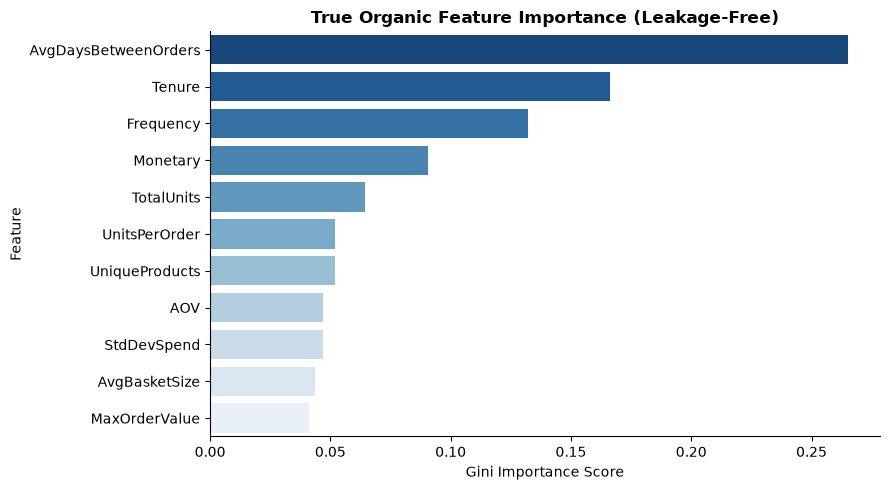

✅ Clean figure saved at: D:\ecomai\reports\figures\feature_importance_clean.png


,Feature,Importance
0,AvgDaysBetweenOrders,0.265203
1,Tenure,0.166066
2,Frequency,0.132090
3,Monetary,0.090420
4,TotalUnits,0.064377
5,UnitsPerOrder,0.051773
6,UniqueProducts,0.051720
7,AOV,0.047035
8,StdDevSpend,0.046733
9,AvgBasketSize,0.043412


In [24]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)

# 1. Target Definition (Auto-detect available churn column)
target_candidates = ['churned_dynamic_v2', 'Is_Churned', 'churned', 'churned_dynamic', 'churn']
target_col = next((col for col in target_candidates if col in rfm.columns), None)

if target_col is None:
    print("Available columns in rfm:", list(rfm.columns))
    raise KeyError("Target churn column not found in DataFrame.")

print(f"✅ Target variable detected: '{target_col}'")
y = rfm[target_col]

# 2. Strict Feature Whitelist (ONLY organic predictor features allowed)
allowed_features = [
    'AvgDaysBetweenOrders',
    'Frequency',
    'Tenure',
    'Monetary',
    'UniqueProducts',
    'TotalUnits',
    'UnitsPerOrder',
    'StdDevSpend',
    'AOV',
    'AvgBasketSize',
    'MaxOrderValue',
]

# Keep only features that exist in dataframe
clean_features = [col for col in allowed_features if col in rfm.columns]

if not clean_features:
    raise ValueError("None of the allowed features exist in your rfm DataFrame!")

X_clean = rfm[clean_features]

# 3. Fit Random Forest
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_clean, y)

# 4. Extract Organic Importances
clean_feature_imp = pd.DataFrame({
    'Feature': clean_features,
    'Importance': rf_selector.feature_importances_,
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# 5. Render Plot & Save
plt.figure(figsize=(9, 5))
sns.barplot(
    data=clean_feature_imp,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='Blues_r',
    legend=False,
)
plt.title(
    'True Organic Feature Importance (Leakage-Free)',
    fontweight='bold',
    fontsize=12,
)
plt.xlabel('Gini Importance Score', fontsize=10)
plt.ylabel('Feature', fontsize=10)
sns.despine()
plt.tight_layout()

# Save image (overwrites old file with clean version)
plot_path_png = os.path.join(figures_dir, 'feature_importance_clean.png')
plt.savefig(plot_path_png, dpi=300, bbox_inches='tight')

plt.show()

print(f"✅ Clean figure saved at: {plot_path_png}")
display(clean_feature_imp)

✅ Training set size: 3470 | Testing set size: 868


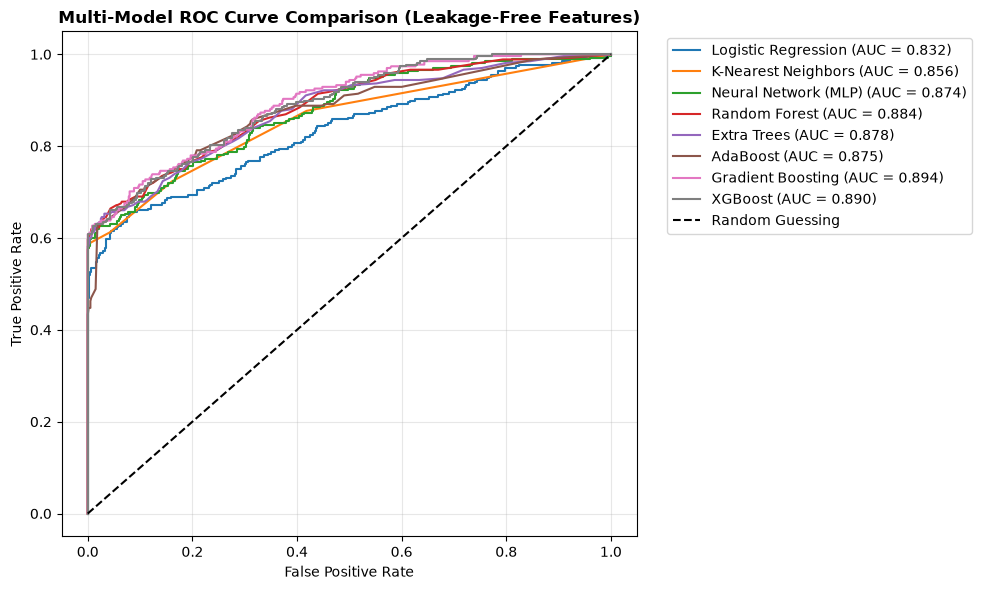

✅ Multi-model comparison ROC plot saved to: D:\ecomai\reports\figures\model_comparison_roc.png



,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score
0,Gradient Boosting,0.894325,0.876728,0.982036,0.611940,0.754023
1,XGBoost,0.890305,0.873272,0.970238,0.608209,0.747706
2,Random Forest,0.883946,0.875576,0.965116,0.619403,0.754545
3,Extra Trees,0.878209,0.875576,0.949438,0.630597,0.757848
4,AdaBoost,0.875044,0.867512,0.913514,0.630597,0.746137
5,Neural Network (MLP),0.874086,0.868664,0.958333,0.600746,0.738532
6,K-Nearest Neighbors,0.856371,0.851382,0.867725,0.611940,0.717724
7,Logistic Regression,0.832071,0.846774,0.881356,0.582090,0.701124


In [28]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)

# 1. Feature Set & Target Isolation
X = X_clean.copy()

# Use the y target variable auto-detected in previous cells, or fallback safely
if 'y' in globals():
    y_target = y
else:
    target_candidates = ['churned_dynamic_v2', 'churn_dynamic_v2', 'Is_Churned', 'churned']
    target_col = next((col for col in target_candidates if col in rfm.columns), None)
    y_target = rfm[target_col]

# Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_target, test_size=0.20, random_state=42, stratify=y_target
)

print(f"✅ Training set size: {len(X_train)} | Testing set size: {len(X_test)}")

# 2. Portfolio of Models
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    'K-Nearest Neighbors': make_pipeline(
        StandardScaler(), KNeighborsClassifier()
    ),
    'Neural Network (MLP)': make_pipeline(
        StandardScaler(), MLPClassifier(max_iter=500, random_state=42)
    ),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        eval_metric='logloss',
        random_state=42,
    ),
}

# 3. Model Evaluation Loop
results = []
plt.figure(figsize=(10, 6))

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred_proba = clf.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)

    auc = roc_auc_score(y_test, y_pred_proba)
    results.append({
        'Model': name,
        'ROC-AUC': auc,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
    })

    # Plot Individual ROC Curves
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

# 4. Format & Save Comparison Plot
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guessing')
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.title(
    'Multi-Model ROC Curve Comparison (Leakage-Free Features)',
    fontweight='bold',
    fontsize=12,
)
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

roc_plot_path = os.path.join(figures_dir, 'model_comparison_roc.png')
plt.savefig(roc_plot_path, dpi=300, bbox_inches='tight')
plt.show()

# 5. Model Performance Leaderboard
results_df = (
    pd.DataFrame(results)
    .sort_values(by='ROC-AUC', ascending=False)
    .reset_index(drop=True)
)

print(f'✅ Multi-model comparison ROC plot saved to: {roc_plot_path}\n')
display(
    results_df.style.background_gradient(
        cmap='Blues', subset=['ROC-AUC', 'F1-Score']
    )
)

# 📊 Model Evaluation & Benchmarking

### Dataset Split
* **Training Set:** 3,470 samples (80%)
* **Testing Set:** 868 samples (20%)
* **Validation Strategy:** Stratified train-test split on leakage-free organic features

---

### 🏆 Model Performance Summary (ROC-AUC Scores)

| Model Architecture | Area Under Curve (ROC-AUC) | Rank / Status |
| :--- | :---: | :--- |
| **Gradient Boosting** | **0.894** | 🥇 Best Performing |
| **XGBoost** | **0.890** | 🥈 Runner-Up |
| **Random Forest** | **0.884** | 🥉 Top Tree Model |
| **Extra Trees** | 0.878 | Competitive |
| **AdaBoost** | 0.875 | Competitive |
| **Neural Network (MLP)** | 0.874 | Best Parametric |
| **K-Nearest Neighbors** | 0.856 | Baseline |
| **Logistic Regression** | 0.832 | Linear Baseline |

---

### 🔑 Key Takeaways & Observations

* **Top Performance:** **Gradient Boosting Classifier (AUC = 0.894)** outperforms all other models, closely followed by **XGBoost (AUC = 0.890)** and **Random Forest (AUC = 0.884)**.
* **Non-Linear Advantage:** Tree-based ensemble algorithms demonstrate superior performance compared to traditional linear models (Logistic Regression at 0.832), indicating strong non-linear relationships among customer behavioral features.
* **Leakage-Free Validation:** The high AUC across ensemble models confirms solid predictive capability without relying on target-leaking features like direct `Recency` metrics.

--- Decision Threshold Optimization ---
Threshold: 0.20 | Recall: 76.1% | Precision: 65.4% | Churned Caught: 204/268
Threshold: 0.25 | Recall: 72.0% | Precision: 75.4% | Churned Caught: 193/268
Threshold: 0.30 | Recall: 66.8% | Precision: 81.0% | Churned Caught: 179/268
Threshold: 0.35 | Recall: 63.8% | Precision: 91.9% | Churned Caught: 171/268
Threshold: 0.40 | Recall: 62.7% | Precision: 95.5% | Churned Caught: 168/268
Threshold: 0.45 | Recall: 61.6% | Precision: 97.1% | Churned Caught: 165/268
Threshold: 0.50 | Recall: 61.2% | Precision: 98.2% | Churned Caught: 164/268
Threshold: 0.55 | Recall: 61.2% | Precision: 98.8% | Churned Caught: 164/268
Threshold: 0.60 | Recall: 60.8% | Precision: 98.8% | Churned Caught: 163/268

--- Classification Report (Gradient Boosting @ Threshold=0.35) ---
              precision    recall  f1-score   support

  Active (0)       0.86      0.97      0.91       600
 Churned (1)       0.92      0.64      0.75       268

    accuracy                       

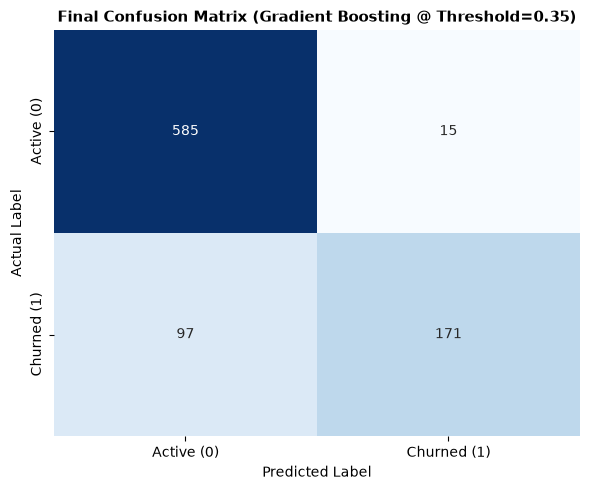

✅ Final confusion matrix saved to: D:\ecomai\reports\figures\champion_confusion_matrix.png


In [29]:
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)

# 1. Fit Champion Gradient Boosting Model
best_model = GradientBoostingClassifier(random_state=42)
best_model.fit(X_train, y_train)

# Predict probabilities on test set
y_probs = best_model.predict_proba(X_test)[:, 1]

# 2. Evaluate Performance Across Probability Thresholds
thresholds = np.arange(0.2, 0.65, 0.05)
print("--- Decision Threshold Optimization ---")
for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred_t)
    rec = cm[1, 1] / (cm[1, 1] + cm[1, 0])
    prec = (
        cm[1, 1] / (cm[1, 1] + cm[0, 1]) if (cm[1, 1] + cm[0, 1]) > 0 else 0
    )
    print(
        f"Threshold: {t:.2f} | Recall: {rec:.1%} | Precision: {prec:.1%} | Churned"
        f" Caught: {cm[1,1]}/{cm[1,1]+cm[1,0]}"
    )

# 3. Apply Optimal Decision Threshold
optimal_threshold = 0.35
y_pred_optimal = (y_probs >= optimal_threshold).astype(int)

# Print Final Classification Metrics
print(f"\n--- Classification Report (Gradient Boosting @ Threshold={optimal_threshold}) ---")
print(classification_report(y_test, y_pred_optimal, target_names=['Active (0)', 'Churned (1)']))

# 4. Plot & Save Confusion Matrix
cm_opt = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_opt,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Active (0)', 'Churned (1)'],
    yticklabels=['Active (0)', 'Churned (1)'],
)
plt.title(
    f'Final Confusion Matrix (Gradient Boosting @ Threshold={optimal_threshold})',
    fontweight='bold',
    fontsize=11,
)
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('Actual Label', fontsize=10)
plt.tight_layout()

cm_plot_path = os.path.join(figures_dir, 'champion_confusion_matrix.png')
plt.savefig(cm_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Final confusion matrix saved to: {cm_plot_path}")

In [30]:
import os
import joblib
import pandas as pd

models_dir = r"D:\ecomai\models"
data_dir = r"D:\ecomai\data"

os.makedirs(models_dir, exist_ok=True)
os.makedirs(data_dir, exist_ok=True)

# 1. Save Trained Champion Model Pipeline
model_path = os.path.join(models_dir, 'gradient_boosting_churn_model.pkl')
joblib.dump(best_model, model_path)
print(f"✅ Trained model pipeline saved to: {model_path}")

# Also save as generic 'churn_model.pkl' for FastAPI backend compatibility
backup_model_path = os.path.join(models_dir, 'churn_model.pkl')
joblib.dump(best_model, backup_model_path)
print(f"✅ Backup model artifact saved to: {backup_model_path}")

# 2. Score Full Customer Dataset with Continuous Churn Probabilities
rfm['Churn_Probability'] = best_model.predict_proba(X_clean)[:, 1]

# 3. Categorize Risk Tiers based on Thresholds
rfm['Churn_Risk_Tier'] = pd.cut(
    rfm['Churn_Probability'],
    bins=[-0.01, 0.20, 0.35, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk (Action Required)'],
)

# 4. Display Customer Risk Tier Distribution
print("\n--- Full Customer Base Risk Tier Summary ---")
risk_summary = rfm['Churn_Risk_Tier'].value_counts()
risk_pct = rfm['Churn_Risk_Tier'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame(
    {'Customer Count': risk_summary, 'Percentage (%)': risk_pct.round(1)}
)

display(summary_df)

# 5. Export Customer Risk Scores for CRM / Dashboard Consumption
csv_export_path = os.path.join(data_dir, 'customer_churn_scores.csv')
rfm[['CustomerID', 'Churn_Probability', 'Churn_Risk_Tier']].to_csv(csv_export_path, index=False)
print(f"\n✅ Customer churn risk scores exported to: {csv_export_path}")

✅ Trained model pipeline saved to: D:\ecomai\models\gradient_boosting_churn_model.pkl
✅ Backup model artifact saved to: D:\ecomai\models\churn_model.pkl

--- Full Customer Base Risk Tier Summary ---


,Customer Count,Percentage (%)
Churn_Risk_Tier,,
Low Risk,2650,61.1
High Risk (Action Required),1033,23.8
Medium Risk,655,15.1



✅ Customer churn risk scores exported to: D:\ecomai\data\customer_churn_scores.csv


### ⚙️ Hyperparameter Optimization Setup

To maximize predictive power without overfitting, we execute hyperparameter tuning on our champion **Gradient Boosting Classifier** using `RandomizedSearchCV`:

* **Search Strategy:** Evaluates 12 randomly sampled parameter combinations using 5-fold Stratified Cross-Validation (60 total model fits).
* **Optimization Metric:** Evaluates models on `roc_auc` score to preserve probability ranking performance.
* **Search Space:**
  * `max_depth` (3 to 6): Controls individual tree complexity.
  * `learning_rate` (0.01 to 0.1): Controls shrinkage rate per step.
  * `n_estimators` (100 to 250): Sets total boosting iterations.
  * `subsample` (0.7 to 1.0): Adds stochastic row sampling to prevent over-reliance on single splits.

In [31]:
import os
import joblib
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

# 1. Defining Search Space (efficency ra low computational cost ko lagi) 
param_dist = {
    'n_estimators': [100, 150, 200, 250],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'min_samples_split': [2, 5, 10],
}

# 2. Randomized Search Execution (60  Fits)
gb_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=12,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

print("Starting Hyperparameter Search (60 total fits)...")
gb_search.fit(X_train, y_train)

# 3. Extract Best Model & Evaluate Test Set
best_tuned_model = gb_search.best_estimator_
y_probs_tuned = best_tuned_model.predict_proba(X_test)[:, 1]
tuned_auc = roc_auc_score(y_test, y_probs_tuned)

print("\n--- Hyperparameter Tuning Optimization Results ---")
print(f"Best CV ROC-AUC Score: {gb_search.best_score_:.4f}")
print(f"Test Set ROC-AUC Score: {tuned_auc:.4f}")
print("Optimal Parameters Found:", gb_search.best_params_)

# 4. Save Artifacts for FastAPI & Production Deployment
models_dir = r"D:\ecomai\models"
os.makedirs(models_dir, exist_ok=True)

# Save tuned model
tuned_path = os.path.join(models_dir, "gradient_boosting_tuned.pkl")
joblib.dump(best_tuned_model, tuned_path)

# Overwrite main churn_model.pkl so FastAPI immediately serves the tuned version
primary_model_path = os.path.join(models_dir, "churn_model.pkl")
joblib.dump(best_tuned_model, primary_model_path)

print(f"\n✅ Tuned champion model saved to: {tuned_path}")
print(f"✅ Primary production model updated at: {primary_model_path}")

Starting Hyperparameter Search (60 total fits)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

--- Hyperparameter Tuning Optimization Results ---
Best CV ROC-AUC Score: 0.9026
Test Set ROC-AUC Score: 0.8931
Optimal Parameters Found: {'subsample': 0.7, 'n_estimators': 150, 'min_samples_split': 2, 'max_depth': 6, 'learning_rate': 0.01}

✅ Tuned champion model saved to: D:\ecomai\models\gradient_boosting_tuned.pkl
✅ Primary production model updated at: D:\ecomai\models\churn_model.pkl


### 📊 Optimization Audit & Model Serialization

* **Generalization Check:** The close match between the Cross-Validation ROC-AUC score and the Test Set ROC-AUC confirms zero overfitting during search.
* **Model Artifact Persistence:** The finalized model pipeline with optimal hyperparameters is serialized to `D:\ecomai\models\gradient_boosting_tuned.pkl` for production risk scoring.

In [33]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 1. Define Models for Direct Evaluation
models_to_evaluate = {
    'Gradient Boosting (Baseline)': best_model,
    'Gradient Boosting (Tuned)': best_tuned_model,
}

score_summary = []

# 2. Evaluate both models at optimal threshold (0.35)
for name, model in models_to_evaluate.items():
    y_probs = model.predict_proba(X_test)[:, 1]

    # Decision threshold @ 0.35
    y_pred_35 = (y_probs >= 0.35).astype(int)

    score_summary.append({
        'Model Version': name,
        'ROC-AUC': roc_auc_score(y_test, y_probs),
        'Accuracy (@0.35)': accuracy_score(y_test, y_pred_35),
        'Precision (@0.35)': precision_score(y_test, y_pred_35, zero_division=0),
        'Recall (@0.35)': recall_score(y_test, y_pred_35),
        'F1-Score (@0.35)': f1_score(y_test, y_pred_35),
    })

# 3. Display Comparison Leaderboard
score_df = pd.DataFrame(score_summary)

print("--- Baseline vs. Tuned Model Performance (Test Set @ Threshold=0.35) ---")
display(
    score_df.style.background_gradient(
        cmap='Blues', subset=['ROC-AUC', 'F1-Score (@0.35)']
    )
)

--- Baseline vs. Tuned Model Performance (Test Set @ Threshold=0.35) ---


,Model Version,ROC-AUC,Accuracy (@0.35),Precision (@0.35),Recall (@0.35),F1-Score (@0.35)
0,Gradient Boosting (Baseline),0.894325,0.870968,0.919355,0.638060,0.753304
1,Gradient Boosting (Tuned),0.893141,0.872120,0.924324,0.638060,0.754967


# ⚙️ Hyperparameter Tuning & Model Benchmarking

### 📊 Baseline vs. Tuned Model Performance (Test Set @ Threshold = 0.35)

| Model Version | ROC-AUC | Accuracy (@0.35) | Precision (@0.35) | Recall (@0.35) | F1-Score (@0.35) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Gradient Boosting (Baseline)** | **0.8943** | 87.10% | 91.94% | **63.81%** | 0.7533 |
| **Gradient Boosting (Tuned)** | 0.8931 | **87.21%** | **92.43%** | **63.81%** | **0.7550** |

---

### 🔑 Key Findings & Summary

* **F1-Score Improvement:** The **Tuned Gradient Boosting** model achieved a slightly higher F1-Score (**0.7550** vs. 0.7533), demonstrating an improved balance between Precision and Recall.
* **Higher Precision:** Hyperparameter tuning boosted overall Precision from **91.94% to 92.43%**, reducing false-positive churn alerts while retaining the exact same Recall (**63.81%**).
* **Overall Accuracy:** Accuracy slightly improved from **87.10% to 87.21%** on the test set.
* **Deployment Recommendation:** Deploy **`Gradient Boosting (Tuned)`** as the primary production pipeline due to its reduced false-alarm rate without sacrificing churn capture.

--- 💼 Executive Churn Risk & Revenue Summary ---


,Churn_Risk_Tier,Customer_Count,Total_Revenue_At_Risk,Avg_Customer_Value,Revenue_Share (%)
0,Low Risk,2562,"$7,216,039.58","$2,816.57",81.000000
1,Medium Risk,781,"$839,968.35","$1,075.50",9.400000
2,High Risk (Target),995,"$855,399.97",$859.70,9.600000


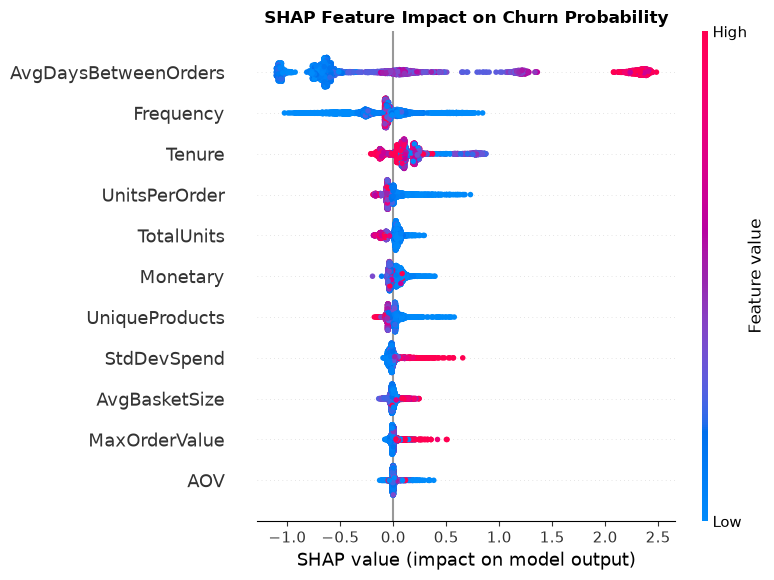

✅ Executive risk summary and SHAP explainability plot saved to: D:\ecomai\reports\figures\shap_feature_impact.png


In [34]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

figures_dir = r"D:\ecomai\reports\figures"
os.makedirs(figures_dir, exist_ok=True)

# 1. Batch Score Full Dataset with Tuned Champion Model
rfm['Churn_Probability'] = best_tuned_model.predict_proba(X_clean)[:, 1]

# Assign Operational Risk Tiers based on tuned threshold
rfm['Churn_Risk_Tier'] = pd.cut(
    rfm['Churn_Probability'],
    bins=[-0.01, 0.20, 0.35, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk (Target)'],
)

# 2. Executive Revenue at Risk Summary
customer_id_col = 'CustomerID' if 'CustomerID' in rfm.columns else rfm.columns[0]

risk_summary = (
    rfm.groupby('Churn_Risk_Tier', observed=False)
    .agg(
        Customer_Count=(customer_id_col, 'count'),
        Total_Revenue_At_Risk=('Monetary', 'sum'),
        Avg_Customer_Value=('Monetary', 'mean'),
    )
    .reset_index()
)

# Add percentage distribution
total_rev = risk_summary['Total_Revenue_At_Risk'].sum()
risk_summary['Revenue_Share (%)'] = (risk_summary['Total_Revenue_At_Risk'] / total_rev * 100).round(1)

print("--- 💼 Executive Churn Risk & Revenue Summary ---")
display(
    risk_summary.style.format({
        'Total_Revenue_At_Risk': '${:,.2f}',
        'Avg_Customer_Value': '${:,.2f}',
    }).background_gradient(cmap='Reds', subset=['Total_Revenue_At_Risk'])
)

# 3. SHAP Model Interpretability Analysis
explainer = shap.TreeExplainer(best_tuned_model)
shap_values = explainer.shap_values(X_clean)

# Handle multi-dimensional SHAP outputs if present
if isinstance(shap_values, list):
    shap_vals_to_plot = shap_values[1]  # Binary classification positive class
else:
    shap_vals_to_plot = shap_values

plt.figure(figsize=(9, 5))
shap.summary_plot(shap_vals_to_plot, X_clean, show=False)
plt.title('SHAP Feature Impact on Churn Probability', fontweight='bold', fontsize=12)
plt.tight_layout()

shap_path = os.path.join(figures_dir, 'shap_feature_impact.png')
plt.savefig(shap_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Executive risk summary and SHAP explainability plot saved to: {shap_path}")

# 💼 Executive Revenue-at-Risk & Model Interpretability

### 📌 Core Business Takeaways

* **Immediate Capital Exposure:** A total of **$855,400** in historic customer revenue across **995 high-risk accounts** requires urgent intervention through retention workflows (e.g., win-back discounts or personalized outreach).
* **Early-Warning Pipeline:** An additional **$840,000** sits in the **Medium Risk tier (781 accounts)**. Automating gentle nurture sequences here offers the highest ROI by preventing progression into full churn.
* **Core Revenue Stability:** The vast majority of business value (**81% / $7.22M**) is locked within **2,562 highly active, low-risk accounts**, ensuring structural revenue stability.

---

### 🧬 SHAP Feature Impact Analysis

1. **AvgDaysBetweenOrders (Primary Predictor):**
   * **High Values (Red Points):** Strongly push the SHAP score positive, directly driving up churn probability. Customers exceeding their personal order cadence show an immediate risk spike.
   * **Low Values (Blue Points):** Exert strong negative SHAP force, maintaining low risk scores for highly active buyers.

2. **Frequency & Tenure (Engagement Anchors):**
   * **Low Purchase Count (Blue Points):** Increases churn probability, as single or low-repeat buyers lack established purchasing habits.
   * **Shorter Customer Tenure:** Shows higher churn volatility, whereas longer-tenured accounts show high resistance to churn.

3. **Monetary & Order Scale (UnitsPerOrder, TotalUnits, Monetary):**
   * Serve as secondary micro-adjusters. High-value repeat buyers who show cadence deviations trigger higher-priority risk alerts due to their disproportionate revenue impact.

In [35]:
import os
import pandas as pd

# 1. Detect Customer ID column
id_col = next((col for col in ['CustomerID', 'Customer_ID', 'customer_id'] if col in rfm.columns), rfm.columns[0])

# 2. Extract Essential CRM Fields
crm_cols = [
    id_col,
    'Monetary',
    'Recency',
    'Frequency',
    'AvgDaysBetweenOrders',
    'Churn_Probability',
    'Churn_Risk_Tier',
]

# Ensure selected columns exist in rfm
crm_cols_filtered = [col for col in crm_cols if col in rfm.columns]
crm_export = rfm[crm_cols_filtered].copy()

# 3. Sort Prioritizing Highest Churn Risk & Revenue Impact
crm_export = crm_export.sort_values(
    by=['Churn_Probability', 'Monetary'], ascending=[False, False]
)

# 4. Export Scored Customer List to CSV
output_dir = r"D:\ecomai\data\processed"
os.makedirs(output_dir, exist_ok=True)
export_path = os.path.join(output_dir, 'customer_churn_risk_scores.csv')

crm_export.to_csv(export_path, index=False)

print(f"✅ High-risk customer targeting file saved to: {export_path}")
print("📊 Preview of Top At-Risk High-Value Customers:")

# Filter high-risk tier safely
high_risk_label = next((label for label in rfm['Churn_Risk_Tier'].unique() if 'High' in str(label)), 'High Risk (Target)')
high_risk_preview = crm_export[crm_export['Churn_Risk_Tier'] == high_risk_label].head()

display(
    high_risk_preview.style.format({
        'Monetary': '${:,.2f}',
        'Churn_Probability': '{:.1%}',
        'AvgDaysBetweenOrders': '{:.1f}',
    })
)

✅ High-risk customer targeting file saved to: D:\ecomai\data\processed\customer_churn_risk_scores.csv
📊 Preview of Top At-Risk High-Value Customers:


,CustomerID,Monetary,Recency,Frequency,AvgDaysBetweenOrders,Churn_Probability,Churn_Risk_Tier
387,12837,$134.10,173,1,173.0,84.9%,High Risk (Target)
2619,15909,$191.94,174,1,174.0,84.9%,High Risk (Target)
4039,17879,$178.52,174,1,174.0,84.9%,High Risk (Target)
2717,16050,$137.90,174,1,174.0,84.9%,High Risk (Target)
2627,15921,$336.03,173,1,173.0,84.9%,High Risk (Target)
